In [76]:
# my jupyter notebook on my computer does not work so I used google drive, change these imports based off of your own computer
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [77]:
from itertools import combinations
from scipy.spatial.distance import pdist, squareform
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [78]:
# Getting Density Data
density_data = pd.read_csv('/content/drive/MyDrive/ProjectCS506/BU Sustainability: Water Bottle stations/Team B/data/density_data_cleaned.csv')
print('Converted Density Data to density_data dataframe')

# Getting Existing Filling Stations Data
inventory_existing_stations = pd.read_csv('/content/drive/MyDrive/ProjectCS506/BU Sustainability: Water Bottle stations/Team B/data/inventory_existing_stations_cleaned.csv')
print('Converted Existing Filling Stations Data to inventory_existing_stations dataframe')


Converted Density Data to density_data dataframe
Converted Existing Filling Stations Data to inventory_existing_stations dataframe


In [79]:
density_data.head()

,date,hour,building_type,building_floor,building_desc,density_cnt,capacity,dc_ratio,longitude,latitude,address,full_address
0,2021-03-31,6,Administrative,3,881 commonwealth avenue,2,70,0.03,-71.1153,42.3514,881 commonwealth,881 commonwealth 3
1,2021-03-31,6,Academic,2,808 commonwealth avenue,3,317,0.01,-71.1117,42.3501,808 commonwealth,808 commonwealth 2
2,2021-03-31,6,Academic,3,808 commonwealth avenue,1,185,0.01,-71.1117,42.3501,808 commonwealth,808 commonwealth 3
3,2021-03-31,6,Administrative,1,163-179 amory street,8,103,0.08,-71.1136,42.3502,163-179 amory,163-179 amory 1
4,2021-03-31,6,Residential,2,112 bay state road,1,3,0.33,-71.0984,42.3499,112 bay state,112 bay state 2


In [80]:
unique_density_data = density_data.drop_duplicates(subset='full_address', keep='first')


existing_filling_stations_with_coords = inventory_existing_stations.merge(
    unique_density_data[['full_address', 'latitude', 'longitude']],
    on='full_address',
    how='left'
)

existing_filling_stations_with_coords.head()

,address,full_address,latitude,longitude
0,100 ashford,100 ashford 1,42.3546,-71.1236
1,8 st. mary's,8 st. mary's 0,NaN,NaN
2,8 st. mary's,8 st. mary's 1,42.3492,-71.1061
3,8 st. mary's,8 st. mary's 3,42.3492,-71.1061
4,8 st. mary's,8 st. mary's 9,42.3492,-71.1061


In [81]:
# filling the NaN values with the longitude and latitude from the closest address and floor
for i in range(len(existing_filling_stations_with_coords) - 1):  # Iterate until the second last row
    # Check if current row's latitude is NaN AND the next row has the same address
    if pd.isna(existing_filling_stations_with_coords.at[i, 'latitude']) and existing_filling_stations_with_coords.at[i, 'address'] == existing_filling_stations_with_coords.at[i + 1, 'address']:
        # Check if the next row has non-NaN values for latitude and longitude
        if not pd.isna(existing_filling_stations_with_coords.at[i + 1, 'latitude']) and not pd.isna(existing_filling_stations_with_coords.at[i + 1, 'longitude']):
            # Copy latitude and longitude from the next row to the current row
            existing_filling_stations_with_coords.at[i, 'latitude'] = existing_filling_stations_with_coords.at[i + 1, 'latitude']
            existing_filling_stations_with_coords.at[i, 'longitude'] = existing_filling_stations_with_coords.at[i + 1, 'longitude']

In [82]:
existing_filling_stations_with_coords = existing_filling_stations_with_coords.dropna(subset=['longitude'])

In [83]:
nan_count_latitude = existing_filling_stations_with_coords['latitude'].isna().sum()

print(f"Number of NaN values in existing stations data: {nan_count_latitude}")

Number of NaN values in existing stations data: 0


In [84]:
existing_filling_stations_with_coords.head()

,address,full_address,latitude,longitude
0,100 ashford,100 ashford 1,42.3546,-71.1236
1,8 st. mary's,8 st. mary's 0,42.3492,-71.1061
2,8 st. mary's,8 st. mary's 1,42.3492,-71.1061
3,8 st. mary's,8 st. mary's 3,42.3492,-71.1061
4,8 st. mary's,8 st. mary's 9,42.3492,-71.1061


# **Using distance algorithm to get distances for each location**

In [85]:
density_data.shape[0]

10905465

In [86]:
unique_count = density_data['full_address'].nunique()

print(f"Number of unique rows based on column 'A': {unique_count}")

Number of unique rows based on column 'A': 1158


In [87]:
locations = density_data.drop_duplicates(subset='full_address', keep='first')
locations.shape[0]

1158

In [88]:
def haversine(lon1, lat1, lon2, lat2):
    lon1, lat1, lon2, lat2 = map(np.radians, [lon1, lat1, lon2, lat2])

    dlon = lon2 - lon1
    dlat = lat2 - lat1
    a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2
    c = 2 * np.arcsin(np.sqrt(a))
    r = 20902231.64 # radius of earth in feet
    return c * r


def find_closest(df1, df2):
    """
    For each row in df2, find the minimum distance to all points in df1
    and add this as a new column 'distance_to_closest_station' in df2.
    """
    min_distances = []
    for _, row2 in df2.iterrows():
        min_distance = np.min([
            haversine(row2['longitude'], row2['latitude'], row1['longitude'], row1['latitude'])
            for _, row1 in df1.iterrows()
        ])
        min_distances.append(min_distance)

    df2['distance_to_closest_station'] = min_distances
    return df2


find_closest(existing_filling_stations_with_coords, locations)
locations.head()


<ipython-input-88-2307043b26f8>:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df2['distance_to_closest_station'] = min_distances


,date,hour,building_type,building_floor,building_desc,density_cnt,capacity,dc_ratio,longitude,latitude,address,full_address,distance_to_closest_station
0,2021-03-31,6,Administrative,3,881 commonwealth avenue,2,70,0.03,-71.1153,42.3514,881 commonwealth,881 commonwealth 3,0.000000
1,2021-03-31,6,Academic,2,808 commonwealth avenue,3,317,0.01,-71.1117,42.3501,808 commonwealth,808 commonwealth 2,0.000000
2,2021-03-31,6,Academic,3,808 commonwealth avenue,1,185,0.01,-71.1117,42.3501,808 commonwealth,808 commonwealth 3,0.000000
3,2021-03-31,6,Administrative,1,163-179 amory street,8,103,0.08,-71.1136,42.3502,163-179 amory,163-179 amory 1,384.444074
4,2021-03-31,6,Residential,2,112 bay state road,1,3,0.33,-71.0984,42.3499,112 bay state,112 bay state 2,139.655632


In [89]:
# locations so that we can graph
locations_graph = locations
locations = locations[['full_address', 'distance_to_closest_station', 'address']]
locations.head()

,full_address,distance_to_closest_station,address
0,881 commonwealth 3,0.000000,881 commonwealth
1,808 commonwealth 2,0.000000,808 commonwealth
2,808 commonwealth 3,0.000000,808 commonwealth
3,163-179 amory 1,384.444074,163-179 amory
4,112 bay state 2,139.655632,112 bay state


In [90]:
locations.to_csv('/content/drive/MyDrive/ProjectCS506/BU Sustainability: Water Bottle stations/Team B/data/address_distances.csv', index=False)

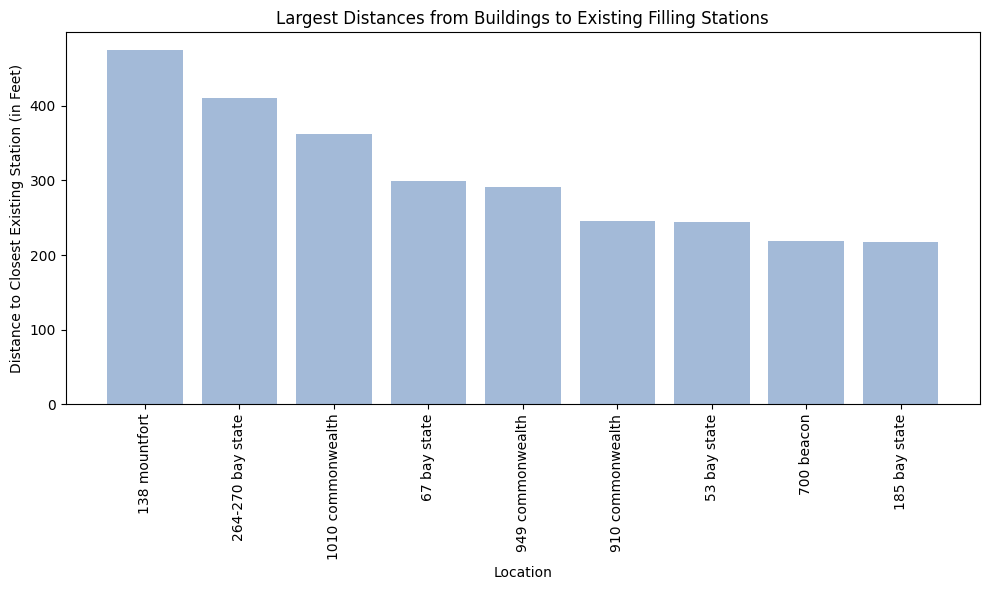

In [96]:
# lets only use academic locations

academic_locations = locations_graph[locations_graph['building_type'] == 'Academic']

locations_sorted = academic_locations.sort_values(by='distance_to_closest_station', ascending=False)

unique_locations = locations_sorted.drop_duplicates(subset=['full_address'], keep='first')

top_10 = unique_locations.head(30)

plt.figure(figsize=(10, 6))
plt.bar(top_10['address'], top_10['distance_to_closest_station'], color='#a3bad8')
plt.xlabel('Location')
plt.ylabel('Distance to Closest Existing Station (in Feet)')
plt.title('Largest Distances from Buildings to Existing Filling Stations')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()